In [1]:
# Exploratory Data Analysis of ~2.2M pseudonymised real-estate property listings (realtor.com data, 1969-2022; locations and ids replaced by invented codes).
# Pipeline: clean data (types, duplicates, missing values) -> column statistics ->
# market analysis per state -> correlation/heatmap + distribution plots -> written insights.
# Run top-to-bottom: cell outputs feed the insight numbers in section 5.

import glob
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)
import matplotlib.pyplot as plt
import numpy as np # linear algebra
import seaborn as sns

# Read file — the CSV is shipped split into <25 MB pieces (GitHub's per-file
# upload limit); every piece repeats the header, so globbing the parts and
# concatenating rebuilds exactly the single-CSV frame.
df = pd.concat([pd.read_csv(p) for p in sorted(glob.glob('data/realtor-data-pseudonymised-part-*.csv'))],
               ignore_index=True)

In [2]:
# 1. Data Cleaning
# 1.1. How many rows and columns in the data frame?
# 1.2. What does the data look like (top 10 rows)?
# 1.3. What are the column data types in the data frame?
# 1.4. Convert data types
# 1.5. What are the column data types in the data frame after converting data types?
# 1.6. Are there duplicates in the data frame?
# 1.7. Remove duplicates
# 1.8. Are there missing values in the data frame?
# 1.9. For the largest amount of missing values inpute mean values 

# 2. Data Statistics
# 2.1. Summarise columns in the data frame
# 2.2. What are the distribution of variables 'state'
# 2.3. What are the distribution of variables 'status'

# 3. Market Analysis
# 3.1. What is the relationships between 'state' and mean 'price'
# 3.1.1. Summary of the least expensive state
# 3.1.2. Summary of the most expensive state
# 3.2. What is the relationship between house features per state?
# 3.3 Filtering data
# 3.3.1. Plot the price of sold properties against the number of bedrooms
# 3.3.2. Plot the price of sold properties against the number of bathrooms
# 3.3.3. Plot the price of sold properties against the acre lot

# 4. Data Correlation
# 4.1 Correlation coefficient heatmap
# 4.2. Visualise correlations
# 4.3. Visualise histograms
# 4.4. Visualise data with their quartiles

# 5. Insights for Real Estate Property Listings


# **1. Data Cleaning**

In [3]:
# 1.1. How many rows and columns in the data frame?
df.shape

(2226382, 12)

In [4]:
# 1.2. What does the data look like (top 10 rows)?
df.head(10)

,brokered_by,status,price,bed,bath,acre_lot,street,city,state,zip_code,house_size,prev_sold_date
0,93665.0,sold,249900.0,2.0,1.0,0.14,158522.0,Region-01-City-13,Region-01,13397.0,842.0,2022-01-28
1,87818.0,for_sale,899999.0,2.0,2.0,0.04,361091.0,Region-02-City-234,Region-02,841.0,1140.0,2018-03-09
2,23758.0,sold,1988000.0,4.0,3.0,0.11,922683.0,Region-02-City-92,Region-02,855.0,2410.0,2021-11-19
3,88121.0,for_sale,999.0,NaN,NaN,0.23,38545.0,Region-20-City-05,Region-20,15140.0,NaN,2008-01-09
4,106615.0,sold,374900.0,3.0,2.0,0.23,438711.0,Region-21-City-160,Region-21,25614.0,1741.0,2021-12-30
5,98747.0,for_sale,89997.0,2.0,1.0,0.14,549913.0,Region-12-City-03,Region-12,13707.0,672.0,2009-09-09
6,87583.0,for_sale,350425.0,4.0,2.0,0.17,926313.0,Region-09-City-12,Region-09,7587.0,1711.0,2019-10-31
7,2862.0,for_sale,515000.0,4.0,3.0,0.51,1044262.0,Region-05-City-23,Region-05,27193.0,2654.0,NaN
8,26319.0,for_sale,90000.0,2.0,1.0,0.14,1129528.0,Region-15-City-16,Region-15,21978.0,948.0,NaN
9,2862.0,for_sale,60000.0,NaN,NaN,1.29,1610205.0,Region-05-City-28,Region-05,18128.0,NaN,NaN


In [5]:
# 1.3. What are the column data types in the data frame?
df.dtypes

brokered_by       float64
status                str
price             float64
bed               float64
bath              float64
acre_lot          float64
street            float64
city                  str
state                 str
zip_code          float64
house_size        float64
prev_sold_date        str
dtype: object

In [6]:
# 1.4. Convert data types
df = df.convert_dtypes()
# Convert datetime  column
df['prev_sold_date'] = pd.to_datetime(df['prev_sold_date'], errors = 'coerce')
# Check types
df.dtypes

brokered_by                Int64
status                    string
price                    Float64
bed                        Int64
bath                       Int64
acre_lot                 Float64
street                     Int64
city                      string
state                     string
zip_code                   Int64
house_size                 Int64
prev_sold_date    datetime64[us]
dtype: object

In [7]:
# 1.5. What are the column data types in the data frame after converting data types?
df.head(10)

,brokered_by,status,price,bed,bath,acre_lot,street,city,state,zip_code,house_size,prev_sold_date
0,93665,sold,249900.0,2,1,0.14,158522,Region-01-City-13,Region-01,13397,842,2022-01-28
1,87818,for_sale,899999.0,2,2,0.04,361091,Region-02-City-234,Region-02,841,1140,2018-03-09
2,23758,sold,1988000.0,4,3,0.11,922683,Region-02-City-92,Region-02,855,2410,2021-11-19
3,88121,for_sale,999.0,<NA>,<NA>,0.23,38545,Region-20-City-05,Region-20,15140,<NA>,2008-01-09
4,106615,sold,374900.0,3,2,0.23,438711,Region-21-City-160,Region-21,25614,1741,2021-12-30
5,98747,for_sale,89997.0,2,1,0.14,549913,Region-12-City-03,Region-12,13707,672,2009-09-09
6,87583,for_sale,350425.0,4,2,0.17,926313,Region-09-City-12,Region-09,7587,1711,2019-10-31
7,2862,for_sale,515000.0,4,3,0.51,1044262,Region-05-City-23,Region-05,27193,2654,NaT
8,26319,for_sale,90000.0,2,1,0.14,1129528,Region-15-City-16,Region-15,21978,948,NaT
9,2862,for_sale,60000.0,<NA>,<NA>,1.29,1610205,Region-05-City-28,Region-05,18128,<NA>,NaT


In [8]:
# 1.6. Are there duplicates in the data frame?
df.duplicated().sum()

np.int64(0)

In [9]:
# 1.7. Remove duplicates
df.drop_duplicates(inplace = True)

In [10]:
# 1.8 Are there missing values in the data frame?
df.isnull().sum()

brokered_by         4533
status                 0
price               1541
bed               481317
bath              511771
acre_lot          325589
street             10866
city                1407
state                  8
zip_code             299
house_size        568484
prev_sold_date    734297
dtype: int64

In [11]:
# 1.9 For the largest amount of missing values inpute mean values 
# Populate NaN values with mean value for 'bed', 'bath', 'acre_lot' and 'house_size'
df['bed'] = df['bed'].fillna(df['bed'].mean().round())
df['bath'] = df['bath'].fillna(df['bath'].mean().round())
df['acre_lot'] = df['acre_lot'].fillna(df['acre_lot'].mean().round())
df['house_size'] = df['house_size'].fillna(df['house_size'].mean().round())
df['price'] = df['price'].fillna(df['price'].mean().round())
df['prev_sold_date'] = df['prev_sold_date'].fillna(pd.NaT) 

In [12]:
# 1.10 Check for missing values in the data frame.
df.isnull().sum()

brokered_by         4533
status                 0
price                  0
bed                    0
bath                   0
acre_lot               0
street             10866
city                1407
state                  8
zip_code             299
house_size             0
prev_sold_date    734297
dtype: int64

# **2. Data Statistics**

In [13]:
# 2.1. Summarise columns in the data frame
df[['bed', 'bath', 'acre_lot', 'house_size', 'price']].describe()

,bed,bath,acre_lot,house_size,price
count,2226382.0,2226382.0,2226382.0,2226382.0,2226382.0
mean,3.216207,2.382325,15.190412,2714.350984,524195.519623
std,1.392195,1.465217,704.842029,697394.104891,2138152.87052
min,1.0,1.0,0.0,4.0,0.0
25%,3.0,2.0,0.17,1456.0,165000.0
50%,3.0,2.0,0.35,2160.0,325000.0
75%,4.0,3.0,3.44,2714.0,550000.0
max,473.0,830.0,100000.0,1040400400.0,2147483600.0


In [14]:
# 2.2. What are the distribution of variables
# 'state'?
df['state'].value_counts(ascending = True)

state
Region-56         1
Region-54       489
Region-53       895
Region-52      2581
Region-51      2600
Region-50      3126
Region-49      3642
Region-48      4039
Region-47      4268
Region-46      4690
Region-45      5065
Region-44      6309
Region-43      6625
Region-42      7243
Region-41      8157
Region-40      8628
Region-39     10059
Region-38     12309
Region-37     14008
Region-36     14557
Region-35     14667
Region-34     14858
Region-33     16255
Region-32     16760
Region-31     18840
Region-30     21074
Region-29     23033
Region-28     23045
Region-27     25815
Region-26     26316
Region-25     32163
Region-24     32293
Region-23     34053
Region-22     37140
Region-21     38041
Region-20     40964
Region-19     42367
Region-18     42390
Region-17     42429
Region-16     43412
Region-15     45145
Region-14     46052
Region-13     48199
Region-12     59207
Region-11     62461
Region-10     68763
Region-09     72825
Region-08     78373
Region-07     80977
Region-06     

In [15]:
# 2.3. What are the distribution of variables
# 'status'?
df['status'].value_counts(ascending = True)

status
ready_to_build      25067
sold               812009
for_sale          1389306
Name: count, dtype: Int64

# **3. Market Analysis**

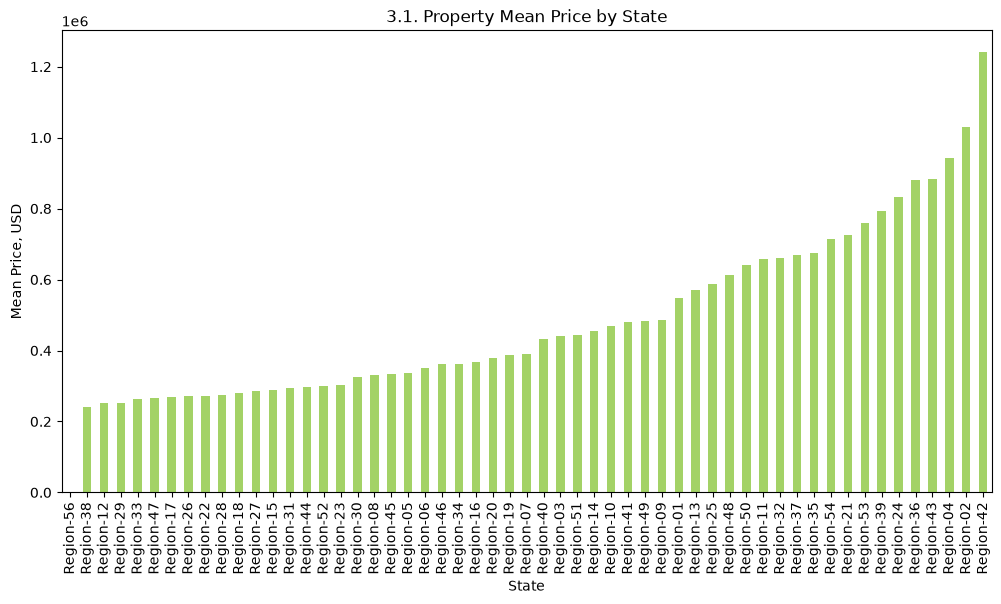

In [16]:
# 3.1. What is the relationships between 'state' and mean 'price'
mean_price_per_state = df.groupby('state')['price'].mean().sort_values()

plt.figure(figsize = (12, 6))
mean_price_per_state.plot(kind = 'bar', color = '#a3d266')
plt.title('3.1. Property Mean Price by State')
plt.xlabel('State')
plt.ylabel('Mean Price, USD')
plt.show()

In [17]:
# 3.1.1. Summary of the least expensive state
state_min_price = df[df['state'] == 'Region-56']
state_min_price.describe()

,brokered_by,price,bed,bath,acre_lot,street,zip_code,house_size,prev_sold_date
count,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1
mean,8457.0,2500.0,3.0,2.0,0.1,1485373.0,2144.0,2714.0,2021-08-06 00:00:00
min,8457.0,2500.0,3.0,2.0,0.1,1485373.0,2144.0,2714.0,2021-08-06 00:00:00
25%,8457.0,2500.0,3.0,2.0,0.1,1485373.0,2144.0,2714.0,2021-08-06 00:00:00
50%,8457.0,2500.0,3.0,2.0,0.1,1485373.0,2144.0,2714.0,2021-08-06 00:00:00
75%,8457.0,2500.0,3.0,2.0,0.1,1485373.0,2144.0,2714.0,2021-08-06 00:00:00
max,8457.0,2500.0,3.0,2.0,0.1,1485373.0,2144.0,2714.0,2021-08-06 00:00:00
std,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,NaN


In [18]:
# 3.1.2. Summary of the most expensive state
state_max_price = df[df['state'] == 'Region-42']
state_max_price.describe()

,brokered_by,price,bed,bath,acre_lot,street,zip_code,house_size,prev_sold_date
count,7235.0,7243.0,7243.0,7243.0,7243.0,7213.0,7243.0,7243.0,4059
mean,54045.639115,1240095.295043,2.846749,2.192047,7.326341,1014309.158187,14663.787519,4901.769847,2010-10-13 14:54:00.798226
min,368.0,1.0,1.0,1.0,0.01,19.0,26.0,116.0,1969-10-01 00:00:00
25%,26620.0,317750.0,2.0,2.0,0.26,499420.0,10520.0,906.0,2005-03-31 00:00:00
50%,52053.0,665000.0,3.0,2.0,1.02,1018677.0,14657.0,1568.0,2014-05-27 00:00:00
75%,86302.0,1200000.0,3.0,2.0,9.515,1520577.0,21058.0,2714.0,2018-12-20 00:00:00
max,110046.0,79000000.0,99.0,113.0,3018.86,2000935.0,30199.0,927828.0,2022-06-10 00:00:00
std,32573.754533,2535521.206167,1.731648,1.752257,56.728366,581273.611867,7682.441184,45273.600949,NaN


In [19]:
# 3.2. What is the relationship between house features per state?
# 'state', 'bed', 'bath', house_size' and 'price'
features_per_state = round(df.pivot_table(index = 'state',
                     values = ['bed','bath','acre_lot','house_size','price'],
                     aggfunc = 'mean'),1)
features_per_state.head(10)

,acre_lot,bath,bed,house_size,price
state,,,,,
Region-01,12.1,2.3,3.0,2074.2,548205.4
Region-02,22.3,2.5,3.3,2033.4,1029150.4
Region-03,10.2,2.5,3.3,2393.9,441448.8
Region-04,56.1,2.3,3.2,2192.9,943788.7
Region-05,9.2,2.4,3.1,2375.9,335746.2
Region-06,6.9,2.3,3.1,2121.1,350174.2
Region-07,33.7,2.6,3.4,2427.5,390392.8
Region-08,6.8,2.3,3.3,2187.9,331973.4
Region-09,10.0,2.3,3.1,16390.5,485989.7


In [20]:
# 3.3. Filtered data for exploring
# Status is Sold, State is Region-23,
# Number of bedrooms is less than or equal to 5,
# Number of bathrooms is less than or eaul to4,
# Acre Lot is less than 1000,
# Price is less than USD 2000 000

# Filter data for specified criteria
filtered_data = df[(df['status'] == 'sold') &
                   (df['state'] == 'Region-23') &
                   (df['bed'] <= 5) &
                   (df['bath'] <= 4) &
                   (df['acre_lot'] <= 1000)&
                   (df['price'] <= 2000000)]

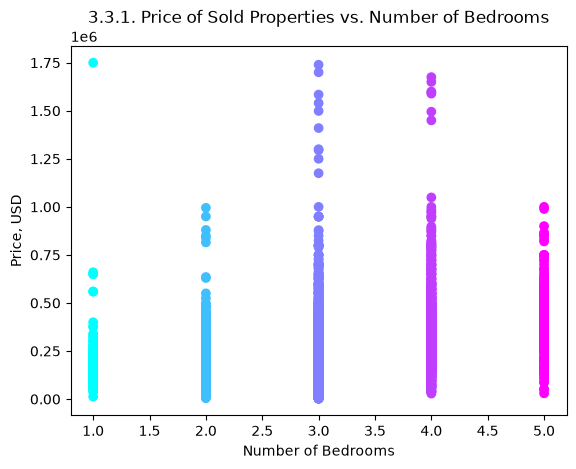

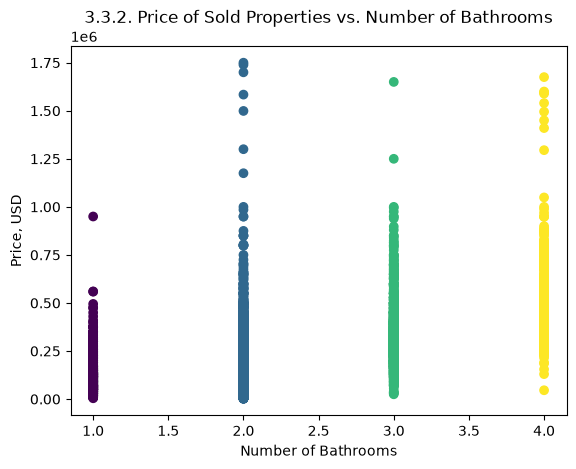

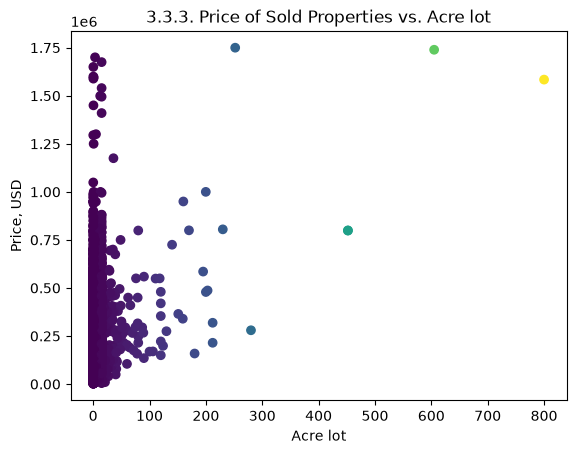

In [21]:
# 3.3.1. Plot the price of sold properties against the number of bedrooms
plt.scatter(filtered_data['bed'], filtered_data['price'], c = filtered_data['bed'], cmap = 'cool')
plt.xlabel('Number of Bedrooms')
plt.ylabel('Price, USD')
plt.title('3.3.1. Price of Sold Properties vs. Number of Bedrooms')
plt.show()

# 3.3.2. Plot the price of sold properties against the number of bathrooms
plt.scatter(filtered_data['bath'], filtered_data['price'], c = filtered_data['bath'], cmap = 'viridis')
plt.xlabel('Number of Bathrooms')
plt.ylabel('Price, USD')
plt.title('3.3.2. Price of Sold Properties vs. Number of Bathrooms')
plt.show()

# 3.3.3. Plot the price of sold properties against the acre lot
plt.scatter(filtered_data['acre_lot'], filtered_data['price'], c = filtered_data['acre_lot'], cmap = 'viridis')
plt.xlabel('Acre lot')
plt.ylabel('Price, USD')
plt.title('3.3.3. Price of Sold Properties vs. Acre lot')
plt.show()

# **4. Data Correlation**
Filtered Data

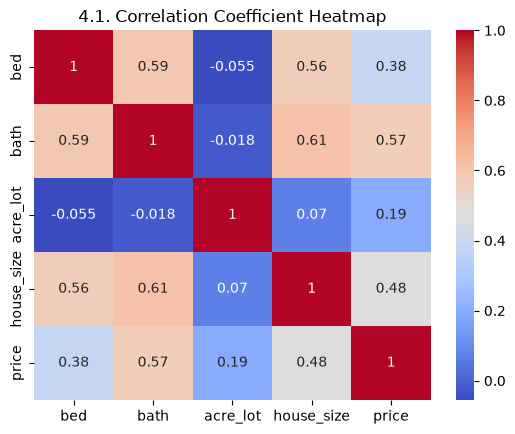

In [22]:
# 4.1 Correlation coefficient heatmap
# Are there any correlations in 'bath, 'bed', 'acre_lot', 'house_size' and 'price'?
correlation_data = filtered_data[['bed', 'bath', 'acre_lot', 'house_size','price']].corr(numeric_only = True)
sns.heatmap(correlation_data, cmap = 'coolwarm', annot = True)
plt.title("4.1. Correlation Coefficient Heatmap")
plt.show()

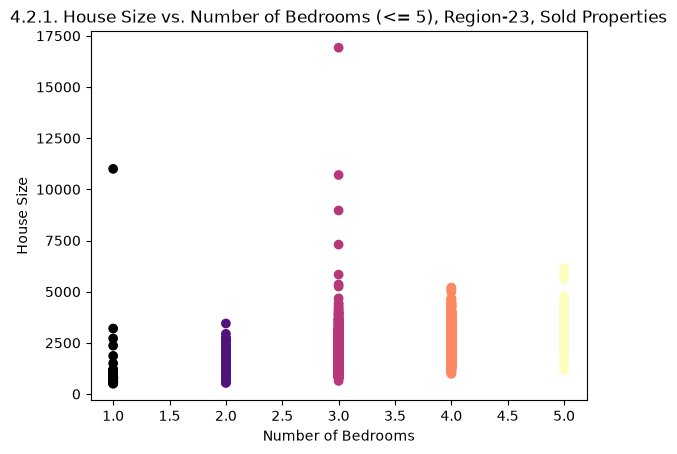

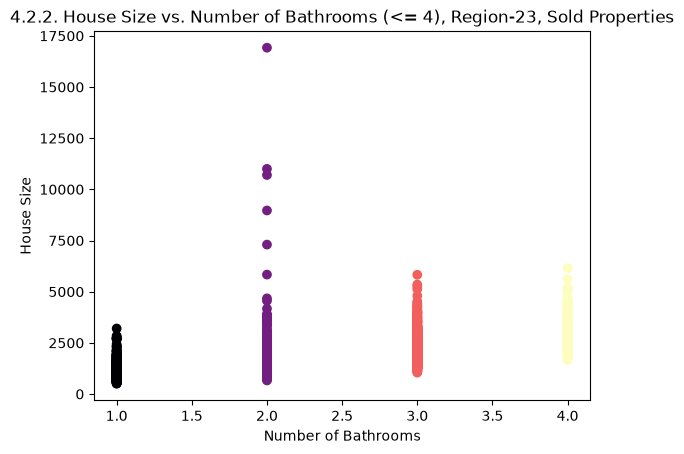

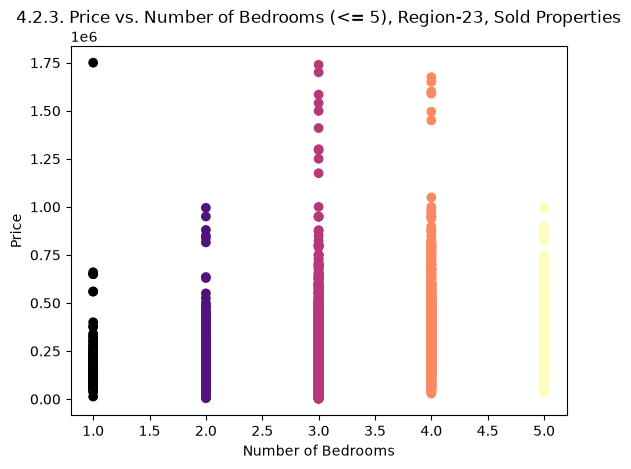

In [23]:
# 4.2. Visualise correlations
# 'house_size' and 'bed'
plt.scatter(filtered_data['bed'], filtered_data['house_size'], c=filtered_data['bed'], cmap='magma')
plt.xlabel('Number of Bedrooms')
plt.ylabel('House Size')
plt.title('4.2.1. House Size vs. Number of Bedrooms (<= 5), Region-23, Sold Properties')
plt.show()

# 'house_size' and 'bath'
plt.scatter(filtered_data['bath'], filtered_data['house_size'], c=filtered_data['bath'], cmap='magma')
plt.xlabel('Number of Bathrooms')
plt.ylabel('House Size')
plt.title('4.2.2. House Size vs. Number of Bathrooms (<= 4), Region-23, Sold Properties')
plt.show()

# 'bed' and 'price'
plt.scatter(filtered_data['bed'], filtered_data['price'], c=filtered_data['bed'], cmap='magma')
plt.xlabel('Number of Bedrooms')
plt.ylabel('Price')
plt.title('4.2.3. Price vs. Number of Bedrooms (<= 5), Region-23, Sold Properties')
plt.show()

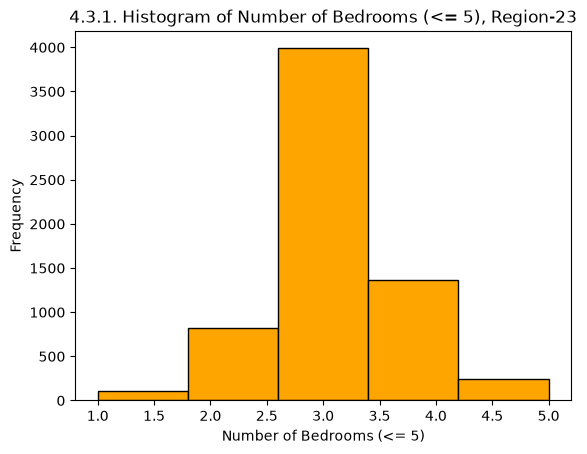

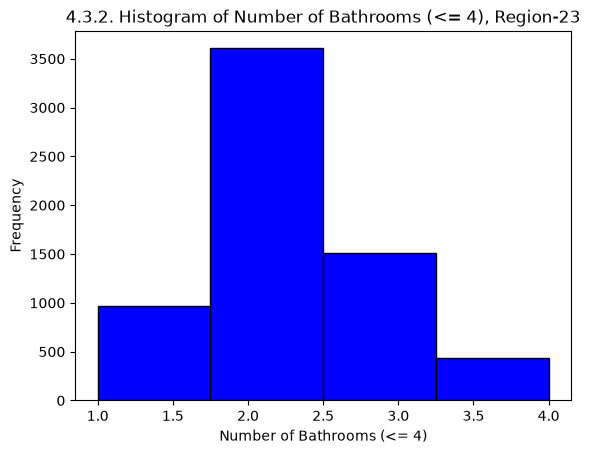

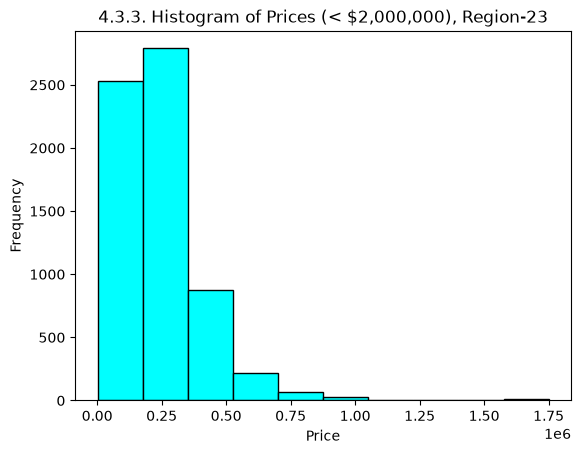

In [24]:
# 4.3. Visualise histograms
# 'bed' variable
plt.hist(filtered_data['bed'], bins=5, color='orange', edgecolor='black')
plt.xlabel('Number of Bedrooms (<= 5)')
plt.ylabel('Frequency')
plt.title('4.3.1. Histogram of Number of Bedrooms (<= 5), Region-23')
plt.show()

# 'bath' variable
plt.hist(filtered_data['bath'], bins=4, color='blue', edgecolor='black')
plt.xlabel('Number of Bathrooms (<= 4)')
plt.ylabel('Frequency')
plt.title('4.3.2. Histogram of Number of Bathrooms (<= 4), Region-23')
plt.show()

# 'price' variable
plt.hist(filtered_data['price'], bins=10, color='cyan', edgecolor='black')
plt.xlabel('Price')
plt.ylabel('Frequency')
plt.title('4.3.3. Histogram of Prices (< $2,000,000), Region-23')
plt.show()

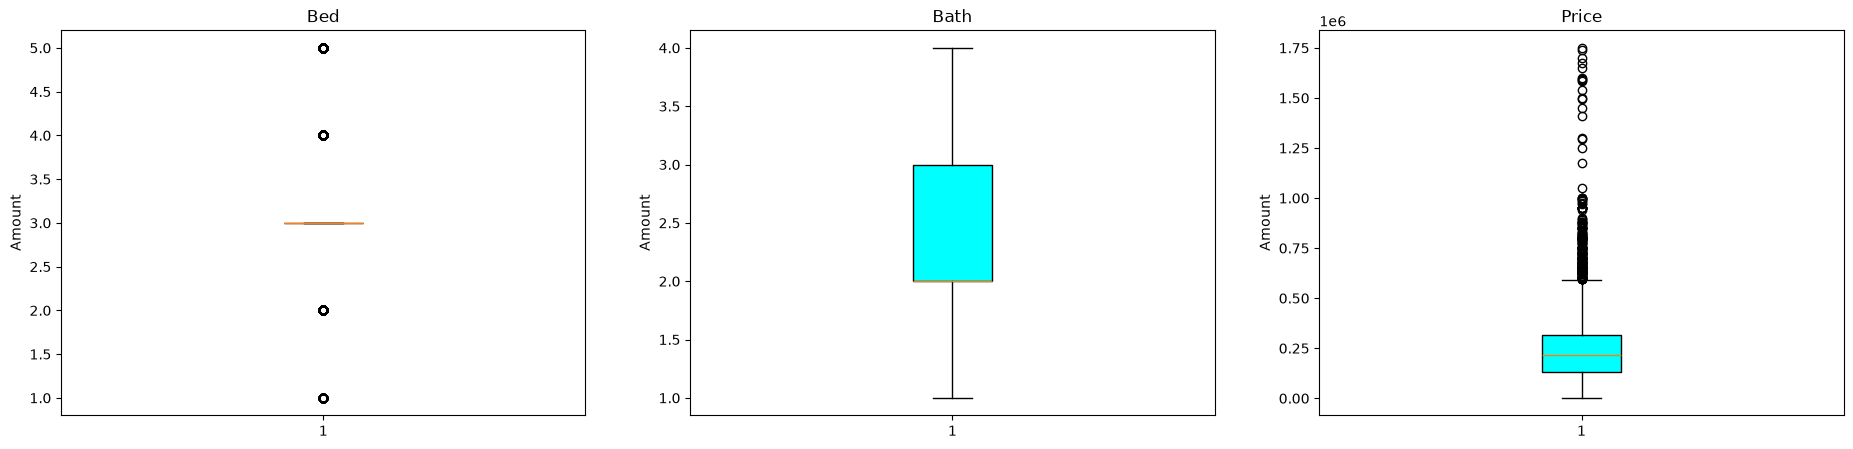

In [25]:
# 4.4. Visualise data with their quartiles
cols = ['bed', 'bath', 'price']

# Create a boxplot for each column
fig, axs = plt.subplots(1, len(cols), figsize=(23, 5))
for i, col in enumerate(cols):
    axs[i].boxplot(filtered_data[col], patch_artist=True, boxprops=dict(facecolor='cyan', color='black'))
    axs[i].set_title(col.capitalize())
    axs[i].set_ylabel('Amount')
plt.show()

# **5. Insights for Real Estate Property Listings**
All listed properties for all regions

Every row is a real listing — only state, city, zip code, street and broker id are
replaced by invented codes — so the numbers below are the real data's.

Two different statistical bases are used below — label each claim so nobody
re-derives it on the wrong one: **whole dataset** (2 226 382 rows after dedupe,
mean-imputed) vs **filter slice** (6 519 rows, defined in {3.3}).

* Whole dataset: region with most listed properties is Region-01 (249 432 — the largest bucket). **{2.2}**
* Whole dataset: highest **mean** price is Region-42 (mean USD 1 240 095 over 7 243 listings); lowest mean price is Region-56 (mean USD 2 500 — its single listing, status for_sale). Phrase it as mean price, NOT "most/least listed properties": Region-01 alone has 249 432 listings, so Region-42 is only price-extreme, not volume-extreme. **{3.1}**
* Filter slice: sold properties in Region-23 with bedrooms ≤ 5, bathrooms ≤ 4, acre lot ≤ 1000, price ≤ USD 2 000 000 → 6 519 rows (the cells and their comments all use ≤, not <). **{3.3}**
* Within the slice: house size correlates with number of bedrooms (0.56) and bathrooms (0.61); bedrooms and bathrooms with each other (0.59). Price follows bathrooms (0.57) more than house size (0.48) or bedrooms (0.38), and barely acre lot (0.19). On the whole dataset house-size correlations collapse to 0.00 because of extreme outliers — quote the slice numbers only for the slice. **{4.1}**
* Slice-only: max prices of 2- and 5-bedroom properties similar (USD 995 000 / 999 999), but 1- and 3-bedroom properties reach USD 1 750 000 / 1 739 260. On the whole dataset the maxima are outliers (USD 2.1e9 for 2 beds, 1.35e8 for 5 beds), so this claim does NOT generalize. **{3.3.1}**
* Slice-only: the modal acre lot 15 (1 317 rows) is an imputation artifact — 1 310 of those rows had no acre lot and got the rounded mean in {1.9}. Among real values the modal lot is 0.16 acres (173 rows); whole dataset 0.17 acres (66 180 rows). **{3.3.3}**
* Slice-only: most sold properties have 3 bedrooms (3 987, of which 588 imputed), then 4 bedrooms (1 367). Whole-dataset modus is also 3 beds but with 1 235 240 rows — don't quote slice counts as global counts. **{4.3}**
* Slice-only: 2 baths most common (3 605, of which 588 imputed); whole dataset modus is also 2 baths (1 258 065). **{4.3.2}**
* Slice-only: most common combination 3 beds / 2 baths (2 801 listings, 588 of them imputed), median price USD 189 900. **{4.4}**